# Label prediction: results

Can the rules predict a patient's label (steroid response, survival, ...)? This notebook only reads the runs saved by `run_predictions.py`; nothing is rerun here.

In [1]:
import prediction_search as ps
import prediction_vis as pv
import run_predictions as rp

runs = ps.saved_runs(rp.PREDICTIONS, rp.UNITS)
best = pv.best_per_prediction(runs)

## 1. Best result per question

- **Small pale dots**: every rule run (every rule set, feature, filter and model), spread up and down a little so they don't hide each other.
- **Hollow blue dot**: the typical rule run (median).
- **Big blue dot**: the best rule run.
- **Teal, orange, brown**: the best score with no rules - cell composition, pathological score, clinical score.
- Rows are sorted by how far the best rule run beats the best of these, per patient.

The best of ~200 runs always looks better than it is. Diagnosis is a control with no reason to be predictable, so its best dot shows how high luck alone reaches.

saved c:\Users\Owner\Documents\script-rule-mining\result_summary\label_prediction\output\best_per_prediction.pdf


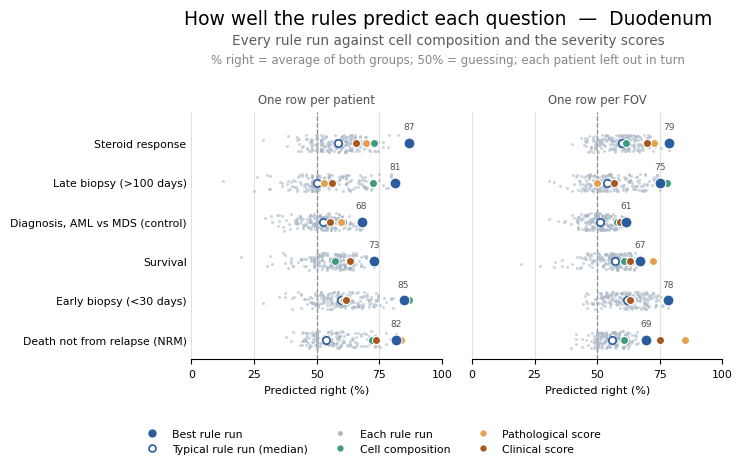

In [2]:
pv.plot_best(runs, save="best_per_prediction.pdf")

The setting behind each best rule run:

In [3]:
best[["prediction", "unit", "best_rules", "best_reference", "best_setting",
      "best_model", "best_auc"]].round(1)

,prediction,unit,best_rules,best_reference,best_setting,best_model,best_auc
0,cortico_response,patient,86.9,72.9,"Attraction + avoidance, all sizes · mean lif...",Lasso logistic regression,95.1
1,cortico_response,FOV,78.6,72.8,"Attraction, pairwise · share of FOVs · in ...",Ridge logistic regression,80.6
2,cause_of_death_nrm_muscle,patient,81.5,83.8,"Attraction, all sizes · share of FOVs · in...",Ridge logistic regression,76.9
3,cause_of_death_nrm_muscle,FOV,69.4,85.2,"Attraction + avoidance, all sizes · share of...",Lasso logistic regression,84.9
4,survival_at_follow_up,patient,72.9,72.9,"Attraction + avoidance, pairwise · mean lift...",Azulay: 2 PCA + linear SVM,69.3
5,survival_at_follow_up,FOV,67.0,72.2,"Attraction + avoidance, pairwise · mean conv...",Ridge logistic regression,67.7
6,days_after_transplant_grouped_under30,patient,84.7,86.8,"Attraction, all sizes · share of FOVs · in...",Ridge logistic regression,85.9
7,days_after_transplant_grouped_under30,FOV,78.3,79.1,"Attraction + avoidance, pairwise · share of ...",Lasso logistic regression,82.9
8,days_after_transplant_grouped_over100,patient,81.2,72.6,"Attraction + avoidance, pairwise · mean lift...",Lasso logistic regression,78.4
9,days_after_transplant_grouped_over100,FOV,75.1,77.7,"Attraction + avoidance, pairwise · mean conv...",Lasso logistic regression,67.1


## 2. Which kind of rule carries the signal

A row per rule set and feature, a column per question. Each cell is the best % right of that rule set and feature, over every filter and model; 50% or less stays white.

Read a **row** across: is this kind of rule good for many questions? Read a **column** down: is the signal spread over many kinds of rule (steady) or in one cell (maybe luck)?

saved c:\Users\Owner\Documents\script-rule-mining\result_summary\label_prediction\output\rule_kinds.pdf


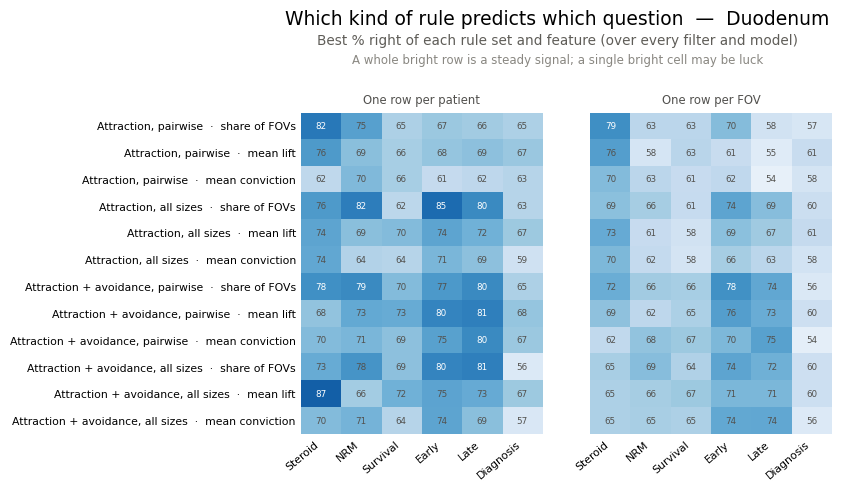

In [4]:
pv.plot_rule_kinds(runs, save="rule_kinds.pdf")

## 3. Are both groups predicted right?

One dot per run: % right of one group (x) against the other (y).

- **Top right**: both groups right - a real prediction.
- **Dashed line**: guessing (50% on average).
- **On an edge**: the model calls almost everyone one group; its score looks fine only because one group is large.

saved c:\Users\Owner\Documents\script-rule-mining\result_summary\label_prediction\output\both_groups_patient.pdf


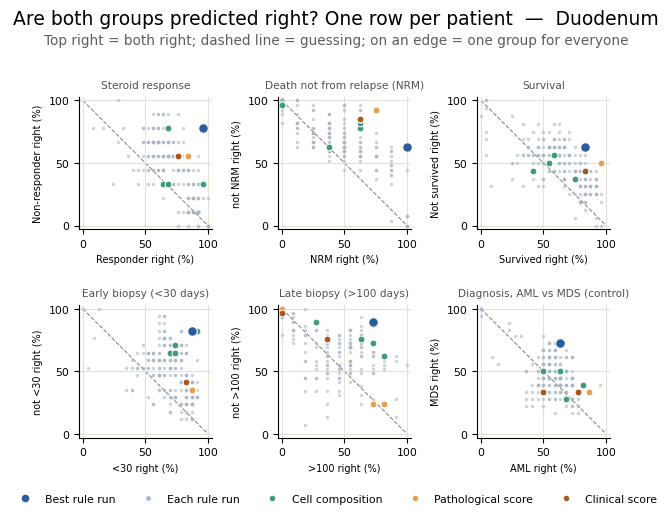

In [5]:
pv.plot_sides(runs, unit="patient", save="both_groups_patient.pdf")

## 4. The rules behind the best run

The biggest weights of the best logistic run on rules. To the right pushes toward the first group (e.g. Responder), to the left toward the other. Blue = attraction, red = avoidance.

These are what one model leaned on, not proof about any single rule.

saved c:\Users\Owner\Documents\script-rule-mining\result_summary\label_prediction\output\weights_cortico_response_patient_plot.pdf


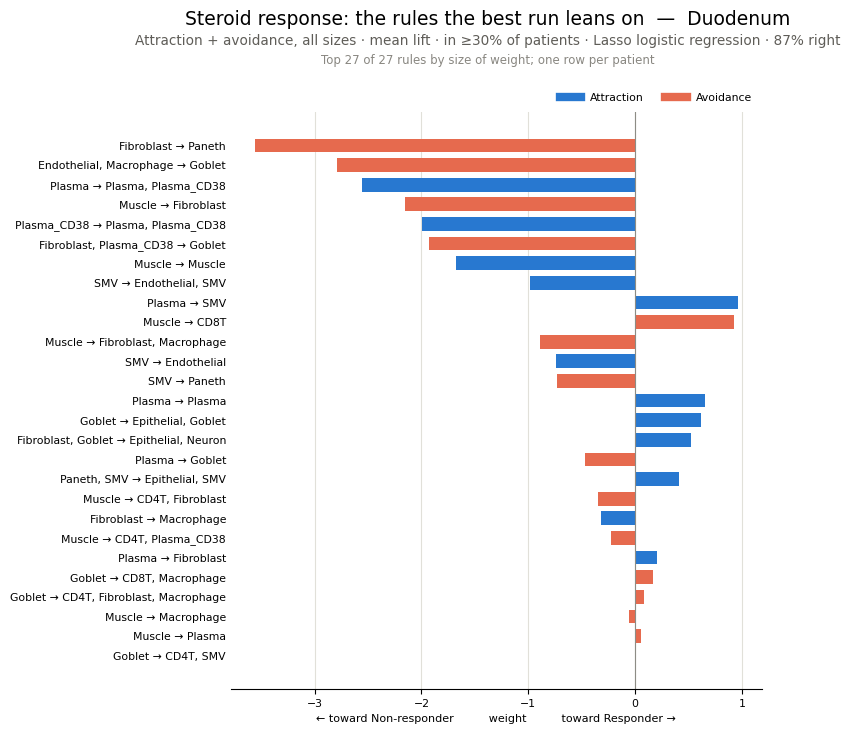

cause_of_death_nrm_muscle: the saved weights are of 'Pathological score only', not rules. Rerun this prediction to save the best rule run's weights.
survival_at_follow_up: the saved weights are of 'Pathological score only', not rules. Rerun this prediction to save the best rule run's weights.
saved c:\Users\Owner\Documents\script-rule-mining\result_summary\label_prediction\output\weights_days_after_transplant_grouped_under30_patient_plot.pdf


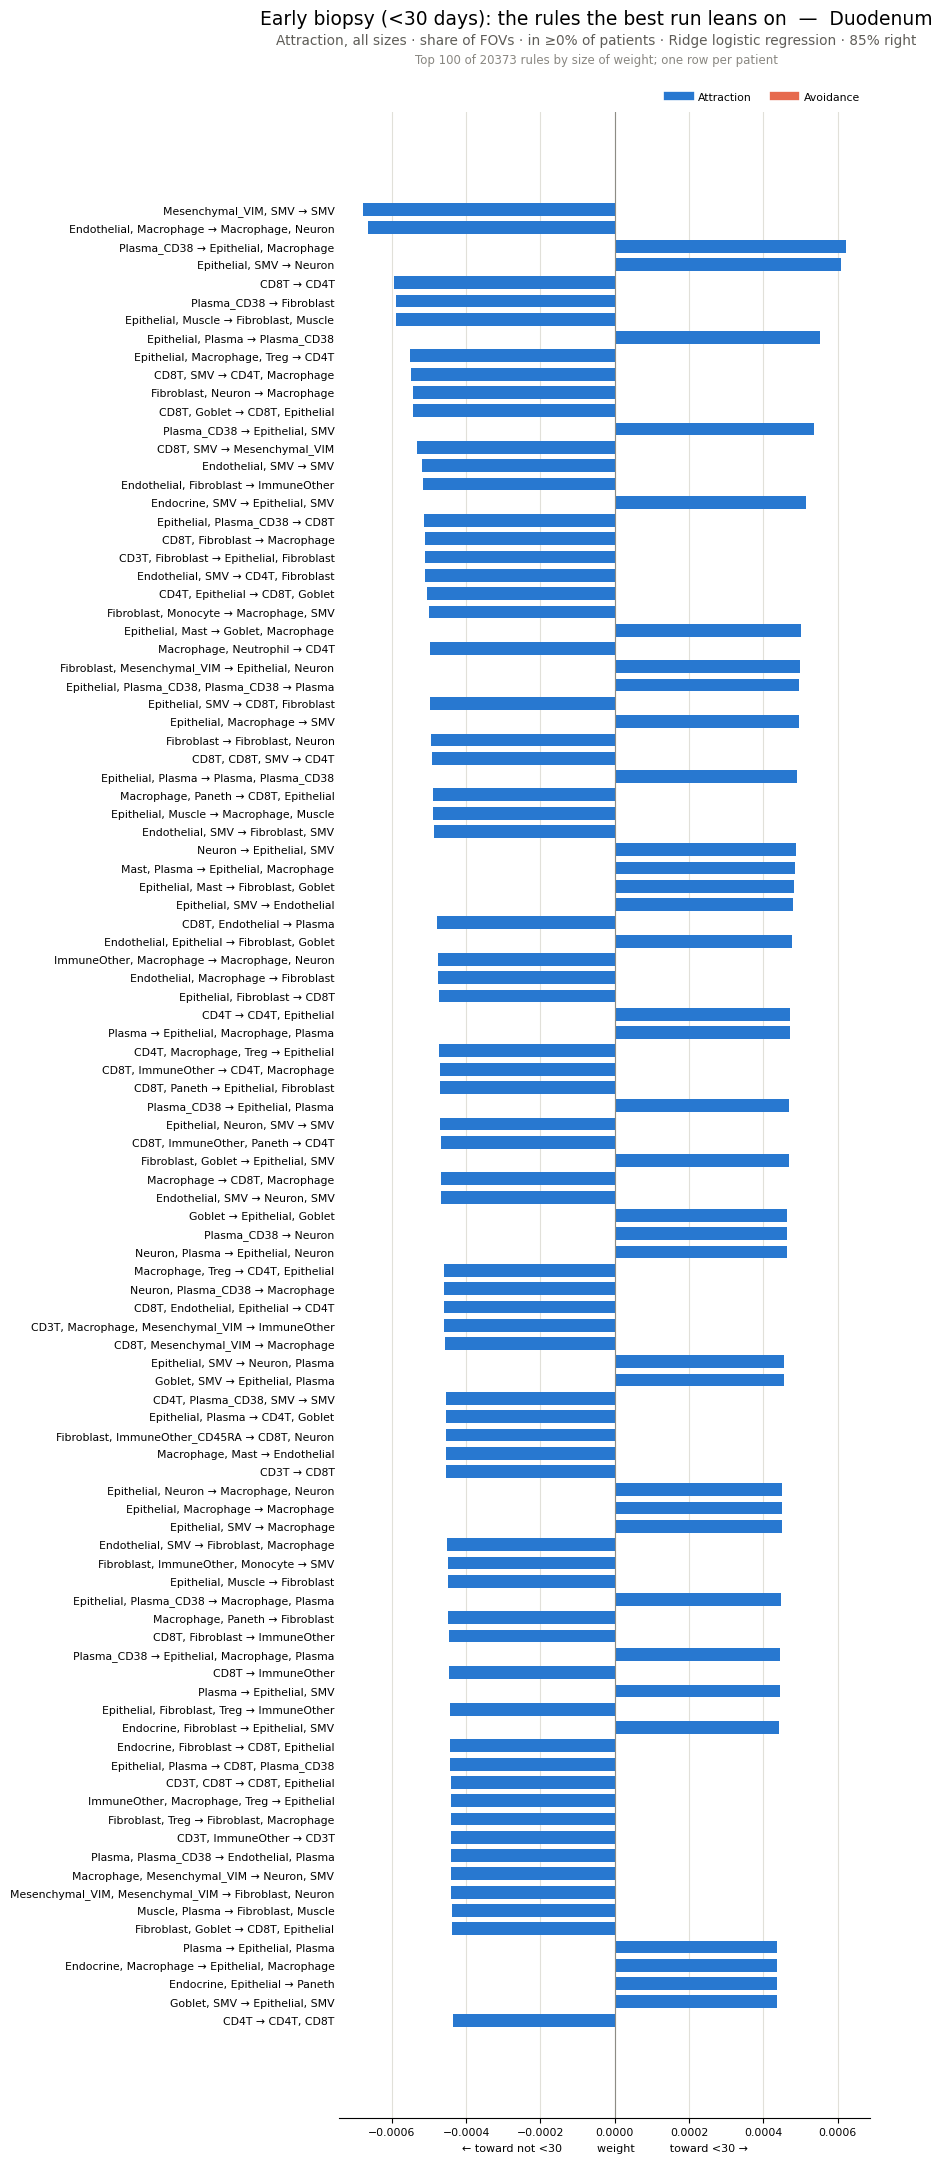

saved c:\Users\Owner\Documents\script-rule-mining\result_summary\label_prediction\output\weights_days_after_transplant_grouped_over100_patient_plot.pdf


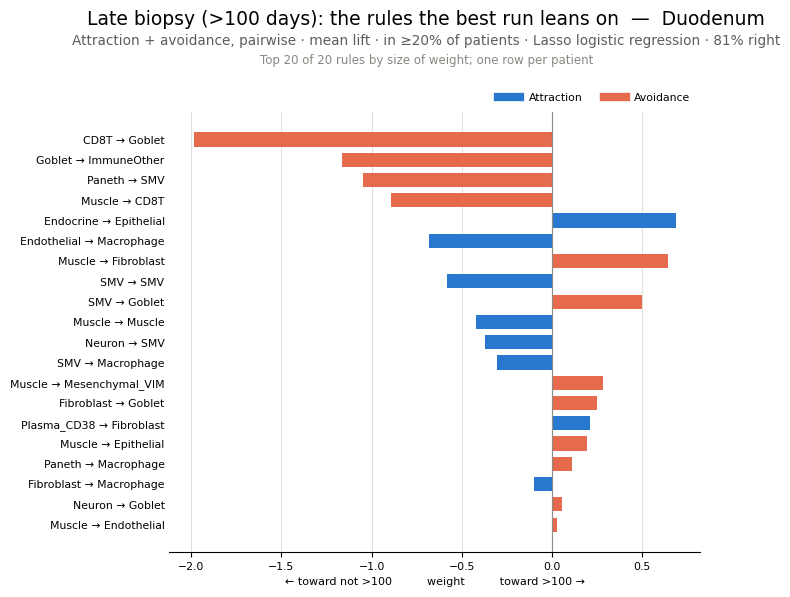

saved c:\Users\Owner\Documents\script-rule-mining\result_summary\label_prediction\output\weights_diagnosis_patient_plot.pdf


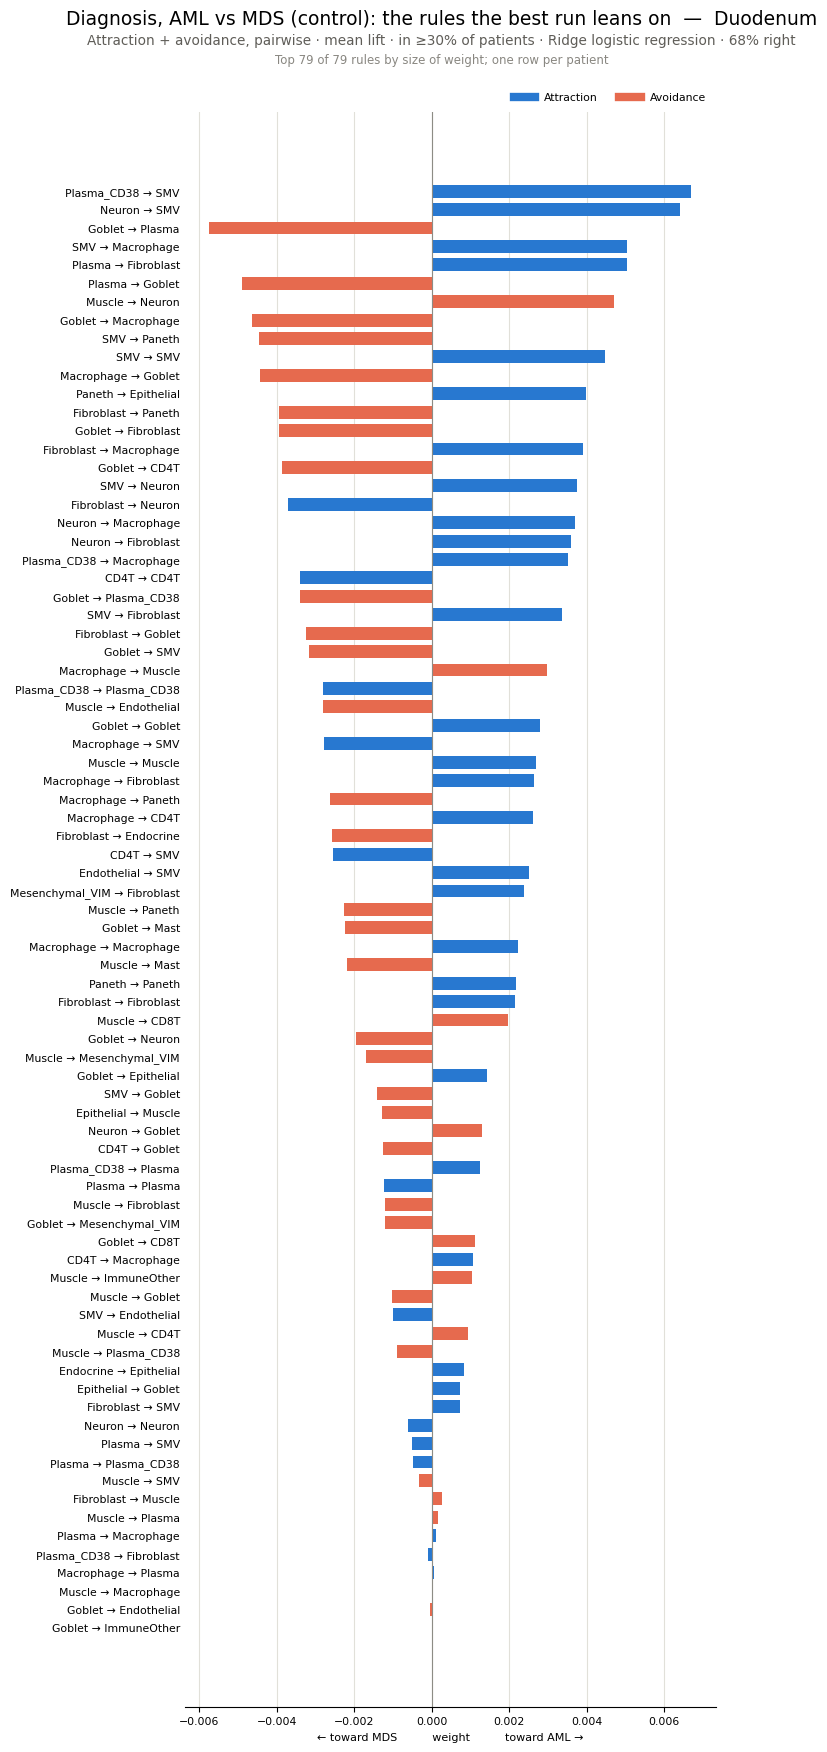

In [6]:
for prediction in rp.PREDICTIONS:
    pv.plot_weights(prediction, unit="patient",
                    save=f"weights_{ps.name_of(prediction)}_patient_plot.pdf")